# Bộ Tối Ưu Hóa (Optimizers): Từ SGD đến Adam

Trong bài trước, chúng ta đã dùng SGD (Stochastic Gradient Descent) cơ bản: $w = w - \eta \cdot \nabla w$. 
Tuy nhiên, nếu bề mặt hàm Loss có dạng thung lũng dốc (dốc mạnh ở 1 trục, lài ở trục kia), SGD sẽ bị dao động (zig-zag) qua lại giữa 2 vách thung lũng và tiến về đáy rất chậm.

**1. SGD với Động lượng (Momentum):**
Mô phỏng một hòn bi lăn xuống dốc. Hòn bi không chỉ đi theo độ dốc hiện tại mà còn giữ lại "quán tính" (vận tốc) của các bước trước đó. Nó giúp triệt tiêu các dao động zig-zag và tăng tốc độ lao xuống đáy.
*   $v_t = \gamma v_{t-1} + \eta \nabla w$ (Vận tốc hiện tại = Quán tính cũ + Lực kéo mới)
*   $w = w - v_t$
*(Trong đó $\gamma$ thường đặt là 0.9)*

**2. RMSprop (Root Mean Square Propagation):**
Điều chỉnh tốc độ học (learning rate) riêng biệt cho từng tham số. Trục nào đang có gradient lớn (dao động mạnh) sẽ bị hãm lại, trục nào gradient nhỏ sẽ được tăng tốc.
*   $s_t = \beta s_{t-1} + (1-\beta) (\nabla w)^2$ (Trung bình bình phương gradient)
*   $w = w - \frac{\eta}{\sqrt{s_t + \epsilon}} \nabla w$

**3. Adam (Adaptive Moment Estimation):**
Adam là sự kết hợp hoàn hảo giữa Momentum (đà di chuyển của trung bình bậc 1) và RMSprop (hãm phanh bằng trung bình bậc 2). Đây là Optimizer mặc định "quốc dân" cho 99% các bài toán Deep Learning hiện nay.
*   $m_t = \beta_1 m_{t-1} + (1-\beta_1) \nabla w$ (Momentum)
*   $v_t = \beta_2 v_{t-1} + (1-\beta_2) (\nabla w)^2$ (RMSprop)
*   Hiệu chỉnh chệch (Bias correction): $\hat{m}_t = \frac{m_t}{1-\beta_1^t}$, $\hat{v}_t = \frac{v_t}{1-\beta_2^t}$
*   Cập nhật: $w = w - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$

In [1]:
import numpy as np

# Định nghĩa bề mặt hàm mất mát giả định dạng thung lũng elip: f(x, y) = 1/2 * x^2 + 5 * y^2
# Đạo hàm (Gradient): df/dx = x, df/dy = 10y
# Trục y có độ dốc gấp 10 lần trục x, gây ra hiện tượng zig-zag cực mạnh cho SGD
def loss_function(w):
    return 0.5 * w[0]**2 + 5.0 * w[1]**2

def gradient(w):
    return np.array([w[0], 10.0 * w[1]])

def optimize(optimizer_name, start_point, lr, iterations):
    w = np.array(start_point, dtype=np.float64)
    path = [w.copy()]
    
    # Khởi tạo tham số cho Momentum và Adam
    v = np.zeros_like(w) # Vận tốc cho Momentum
    m = np.zeros_like(w) # Moment bậc 1 (Adam)
    s = np.zeros_like(w) # Moment bậc 2 (Adam)
    
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8 # Tham số chuẩn của Adam
    
    for t in range(1, iterations + 1):
        grad = gradient(w)
        
        if optimizer_name == 'SGD':
            w -= lr * grad
            
        elif optimizer_name == 'Momentum':
            v = 0.9 * v + lr * grad
            w -= v
            
        elif optimizer_name == 'Adam':
            m = beta1 * m + (1 - beta1) * grad
            s = beta2 * s + (1 - beta2) * (grad ** 2)
            
            # Bias correction
            m_hat = m / (1 - beta1 ** t)
            s_hat = s / (1 - beta2 ** t)
            
            w -= lr * m_hat / (np.sqrt(s_hat) + epsilon)
            
        path.append(w.copy())
    return np.array(path)

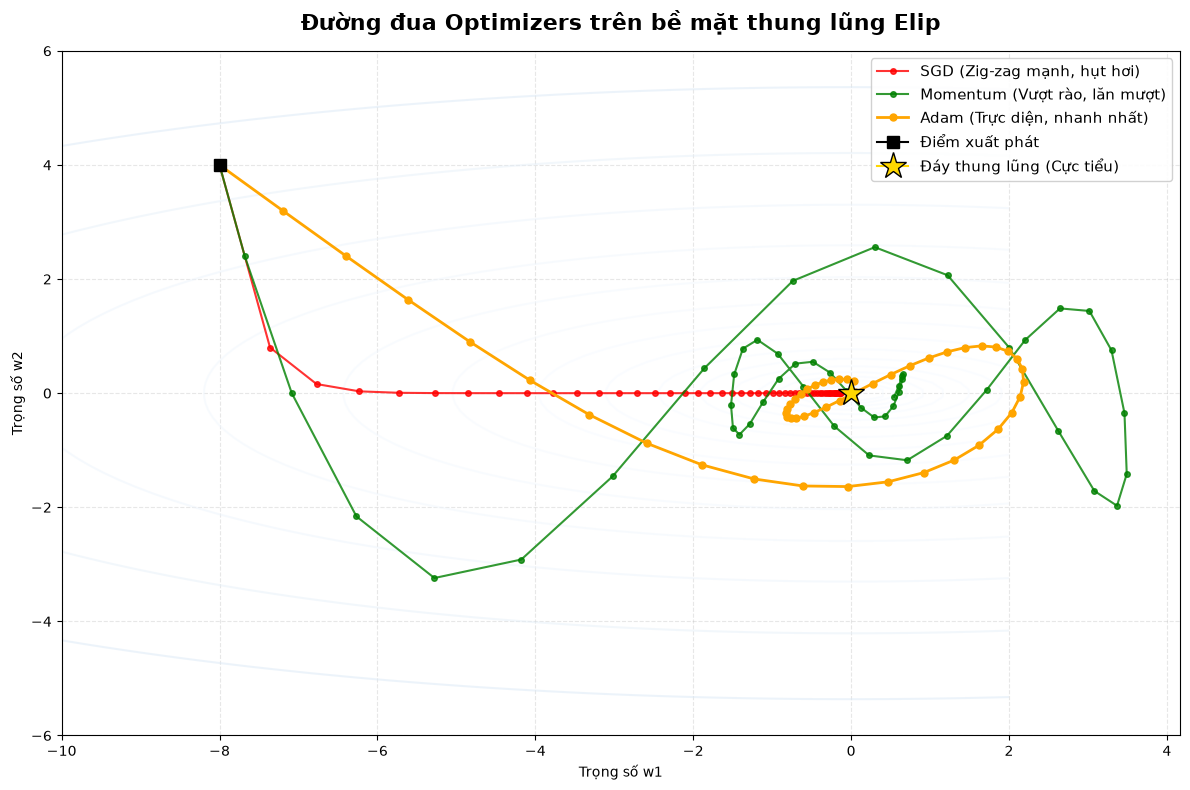

In [2]:
import matplotlib.pyplot as plt

# 1. Chạy mô phỏng 3 thuật toán từ cùng một điểm xuất phát (-8, 4)
start_point = [-8.0, 4.0]
iters = 50

# Learning rate được tinh chỉnh riêng để mỗi thuật toán thể hiện rõ đặc tính
path_sgd = optimize('SGD', start_point, lr=0.08, iterations=iters)
path_momentum = optimize('Momentum', start_point, lr=0.04, iterations=iters)
path_adam = optimize('Adam', start_point, lr=0.8, iterations=iters) # Adam thường chịu được lr lớn hơn

# 2. Tạo không gian bề mặt (Contour plot)
x = np.linspace(-10, 2, 100)
y = np.linspace(-6, 6, 100)
X, Y = np.meshgrid(x, y)
Z = 0.5 * X**2 + 5.0 * Y**2

# 3. Trực quan hóa đường đi
plt.figure(figsize=(12, 8))
# Vẽ bản đồ đường viền (vùng càng sậm màu càng gần cực tiểu toàn cục tại tọa độ 0,0)
contour = plt.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='Blues', alpha=0.5)

# Vẽ quỹ đạo của từng Optimizer
plt.plot(path_sgd[:, 0], path_sgd[:, 1], 'o-', color='red', label='SGD (Zig-zag mạnh, hụt hơi)', markersize=4, alpha=0.8)
plt.plot(path_momentum[:, 0], path_momentum[:, 1], 'o-', color='green', label='Momentum (Vượt rào, lăn mượt)', markersize=4, alpha=0.8)
plt.plot(path_adam[:, 0], path_adam[:, 1], 'o-', color='orange', label='Adam (Trực diện, nhanh nhất)', markersize=5, linewidth=2)

# Đánh dấu điểm bắt đầu và đích đến
plt.plot(start_point[0], start_point[1], marker='s', color='black', markersize=8, label='Điểm xuất phát')
plt.plot(0, 0, marker='*', color='gold', markersize=20, markeredgecolor='black', label='Đáy thung lũng (Cực tiểu)')

plt.title("Đường đua Optimizers trên bề mặt thung lũng Elip", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Trọng số w1")
plt.ylabel("Trọng số w2")
plt.legend(loc='upper right', fontsize=11, framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()